# Gradient boosting frente a regresión logística: en qué mundos gana cada uno

**Perfil:** Cuantitativo y ciencia de datos  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

¿El gradient boosting siempre supera a la regresión logística? Depende de **cómo es la relación verdadera** y de **cuántos datos** hay. Además: ¿cómo se compara de forma **justa**, qué tan fiable es la puntuación del propio CV que elige hiperparámetros, y qué tan fiables son las probabilidades y la importancia de variables?

## Recorrido

1. Cuatro mundos con verdad conocida: lineal, no lineal aditivo, con interacciones y ruidoso con muchas variables inútiles.
2. **Modelos:** logística, logística con términos cuadráticos e interacciones, boosting por defecto y boosting afinado.
3. **Curva de aprendizaje:** exceso de pérdida frente al oráculo (la probabilidad verdadera) según $n$.
4. **Probabilidades:** calibración y recalibración. **Importancia de variables:** impureza frente a permutación.
5. **Fiabilidad del CV que elige:** sesgo y dispersión frente a datos frescos, incluido un mundo sin señal.
6. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, KFold, cross_val_predict
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from sklearn.calibration import CalibratedClassifierCV
from sklearn.inspection import permutation_importance

## 2. Cuatro mundos con verdad conocida

La **probabilidad verdadera** $p(x)$ se conoce en cada mundo, de modo que el **oráculo** (predecir $p(x)$) es el techo: ningún modelo puede superarlo en pérdida logarítmica. El *exceso de pérdida* frente al oráculo mide cuánto se pierde por no conocer la forma funcional.

| mundo | $\operatorname{logit}p(x)$ | variables |
|---|---|---|
| `lineal` | $0{,}9x_0-0{,}7x_1+0{,}5x_2$ | 8 |
| `no_lineal` | $1{,}2\sin(1{,}5x_0)+0{,}8x_1^2+0{,}7x_2$ | 8 |
| `interacciones` | $1{,}5x_0x_1+1{,}2\,\mathbf 1\{x_2>0\}\mathbf 1\{x_3>0{,}3\}$ | 8 |
| `ruidoso` | $0{,}5x_0+0{,}4x_1$ | 30 (28 inútiles) |

In [2]:
MUNDOS = ["lineal", "no_lineal", "interacciones", "ruidoso"]
def logit_verdadero(X, mundo):
    if mundo == "lineal": return 0.9 * X[:, 0] - 0.7 * X[:, 1] + 0.5 * X[:, 2]
    if mundo == "no_lineal": return 1.2 * np.sin(1.5 * X[:, 0]) + 0.8 * X[:, 1] ** 2 + 0.7 * X[:, 2]
    if mundo == "interacciones": return 1.5 * X[:, 0] * X[:, 1] + 1.2 * ((X[:, 2] > 0) & (X[:, 3] > 0.3))
    if mundo == "ruidoso": return 0.5 * X[:, 0] + 0.4 * X[:, 1]

_OFFSET = {}
def offset(mundo):
    # intercepto tal que la tasa de positivos sea ~25% (se calcula una vez con una muestra grande)
    if mundo not in _OFFSET:
        X = np.random.default_rng(0).standard_normal((200_000, 30 if mundo == "ruidoso" else 8)); z = logit_verdadero(X, mundo)
        lo, hi = -10, 10
        for _ in range(60):
            mid = (lo + hi) / 2
            if (1 / (1 + np.exp(-(z + mid)))).mean() > 0.25: hi = mid
            else: lo = mid
        _OFFSET[mundo] = (lo + hi) / 2
    return _OFFSET[mundo]

def generar(mundo, n, seed):
    rg = np.random.default_rng(seed); p = 30 if mundo == "ruidoso" else 8
    X = rg.standard_normal((n, p)); pv = 1 / (1 + np.exp(-(logit_verdadero(X, mundo) + offset(mundo))))
    return X, (rg.random(n) < pv).astype(int), pv

for m in MUNDOS:
    X, y, pv = generar(m, 50_000, 1)
    print(f"{m:14s}: tasa de positivos = {y.mean():.3f} | AUC del oraculo = {roc_auc_score(y, pv):.3f} | log-loss del oraculo = {log_loss(y, pv):.4f}")

lineal        : tasa de positivos = 0.250 | AUC del oraculo = 0.780 | log-loss del oraculo = 0.4625


no_lineal     : tasa de positivos = 0.251 | AUC del oraculo = 0.825 | log-loss del oraculo = 0.4196


interacciones : tasa de positivos = 0.250 | AUC del oraculo = 0.791 | log-loss del oraculo = 0.4434


ruidoso       : tasa de positivos = 0.251 | AUC del oraculo = 0.669 | log-loss del oraculo = 0.5283


## 3. Los modelos

1. **Logística:** $\ell_2$, $C=1$, variables estandarizadas.
2. **Logística + cuadráticos e interacciones:** `PolynomialFeatures(2)` + estandarización + $\ell_2$ ($C=0{,}3$). Captura efectos cuadráticos y productos de pares; **no** captura $\sin$ ni umbrales.
3. **Boosting (defecto):** `HistGradientBoostingClassifier` con sus valores por defecto.
4. **Boosting afinado:** búsqueda en malla pequeña (tasa de aprendizaje, hojas máximas) con validación cruzada de 3 pliegues **dentro** del entrenamiento.

In [3]:
def modelos(afinar=True):
    m = {"logit": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)),
         "logit + cuad/inter": make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LogisticRegression(C=0.3, max_iter=3000)),
         "boosting defecto": HistGradientBoostingClassifier(random_state=0)}
    if afinar:
        m["boosting afinado"] = GridSearchCV(HistGradientBoostingClassifier(random_state=0, max_iter=150),
                                             {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [4, 15]}, cv=KFold(3, shuffle=True, random_state=0), scoring="neg_log_loss", n_jobs=1)
    return m

def evaluar(mundo, n, seed, n_test=15_000, afinar=True):
    X, y, _ = generar(mundo, n, seed); Xt, yt, pt = generar(mundo, n_test, 999_000 + seed)
    ll_o = log_loss(yt, pt); out = []
    for nombre, mod in modelos(afinar).items():
        mod.fit(X, y); p = np.clip(mod.predict_proba(Xt)[:, 1], 1e-9, 1 - 1e-9)
        out.append({"mundo": mundo, "n": n, "modelo": nombre, "AUC": roc_auc_score(yt, p), "logloss": log_loss(yt, p), "exceso_logloss": log_loss(yt, p) - ll_o, "Brier": brier_score_loss(yt, p), "AUC_oraculo": roc_auc_score(yt, pt)})
    return out

# una muestra concreta
pd.DataFrame(evaluar("interacciones", 3000, 1)).set_index("modelo")[["AUC", "logloss", "exceso_logloss", "AUC_oraculo"]].round(4)

,AUC,logloss,exceso_logloss,AUC_oraculo
modelo,,,,
logit,0.5664,0.5587,0.1201,0.7970
logit + cuad/inter,0.7794,0.4534,0.0148,0.7970
boosting defecto,0.7432,0.5007,0.0621,0.7970
boosting afinado,0.7673,0.4687,0.0301,0.7970


## 4. Curva de aprendizaje por mundo

Para cada mundo y cada $n$ se entrenan los modelos en 5 muestras distintas y se promedia el **exceso de pérdida logarítmica** frente al oráculo (menor es mejor; 0 sería perfecto).

In [4]:
NS = [500, 2000, 8000]
filas = []
for mundo in MUNDOS:
    for n in NS:
        for s in range(5): filas.extend(evaluar(mundo, n, 100 * n + s))
res = pd.DataFrame(filas)
curva = res.groupby(["mundo", "n", "modelo"])[["exceso_logloss", "AUC"]].mean().reset_index()
curva.pivot_table(index=["mundo", "n"], columns="modelo", values="exceso_logloss").round(4)

modelo              boosting afinado  boosting defecto  logit  \
mundo         n                                                 
interacciones 500             0.0808            0.2244 0.1239   
              2000            0.0397            0.0846 0.1189   
              8000            0.0186            0.0238 0.1178   
lineal        500             0.0343            0.2287 0.0103   
              2000            0.0124            0.0884 0.0026   
              8000            0.0071            0.0214 0.0004   
no_lineal     500             0.0455            0.2409 0.1108   
              2000            0.0221            0.0829 0.1058   
              8000            0.0074            0.0219 0.1059   
ruidoso       500             0.0283            0.2535 0.0378   
              2000            0.0103            0.0933 0.0092   
              8000            0.0032            0.0226 0.0021   

modelo              logit + cuad/inter  
mundo         n                         
interacciones 500               0.0698  
              2000              0.0185  
              8000              0.0107  
lineal        500               0.0495  
              2000              0.0112  
              8000              0.0024  
no_lineal     500               0.0804  
              2000              0.0351  
              8000              0.0265  
ruidoso       500               0.7640  
              2000              0.3208  
              8000              0.0380

In [5]:
t = curva.pivot_table(index=["mundo", "n"], columns="modelo", values="exceso_logloss")
print("Lectura (exceso de log-loss frente al oraculo; menor = mejor):")
for mundo in MUNDOS:
    for n in NS:
        f = t.loc[(mundo, n)]; mejor = f.idxmin()
        print(f"  {mundo:14s} n={n:<5d}: mejor = {mejor:20s} ({f.min():.4f}) | logit {f['logit']:.4f} | boosting afinado {f['boosting afinado']:.4f}")

Lectura (exceso de log-loss frente al oraculo; menor = mejor):
  lineal         n=500  : mejor = logit                (0.0103) | logit 0.0103 | boosting afinado 0.0343
  lineal         n=2000 : mejor = logit                (0.0026) | logit 0.0026 | boosting afinado 0.0124
  lineal         n=8000 : mejor = logit                (0.0004) | logit 0.0004 | boosting afinado 0.0071
  no_lineal      n=500  : mejor = boosting afinado     (0.0455) | logit 0.1108 | boosting afinado 0.0455
  no_lineal      n=2000 : mejor = boosting afinado     (0.0221) | logit 0.1058 | boosting afinado 0.0221
  no_lineal      n=8000 : mejor = boosting afinado     (0.0074) | logit 0.1059 | boosting afinado 0.0074
  interacciones  n=500  : mejor = logit + cuad/inter   (0.0698) | logit 0.1239 | boosting afinado 0.0808
  interacciones  n=2000 : mejor = logit + cuad/inter   (0.0185) | logit 0.1189 | boosting afinado 0.0397
  interacciones  n=8000 : mejor = logit + cuad/inter   (0.0107) | logit 0.1178 | boosting afinado

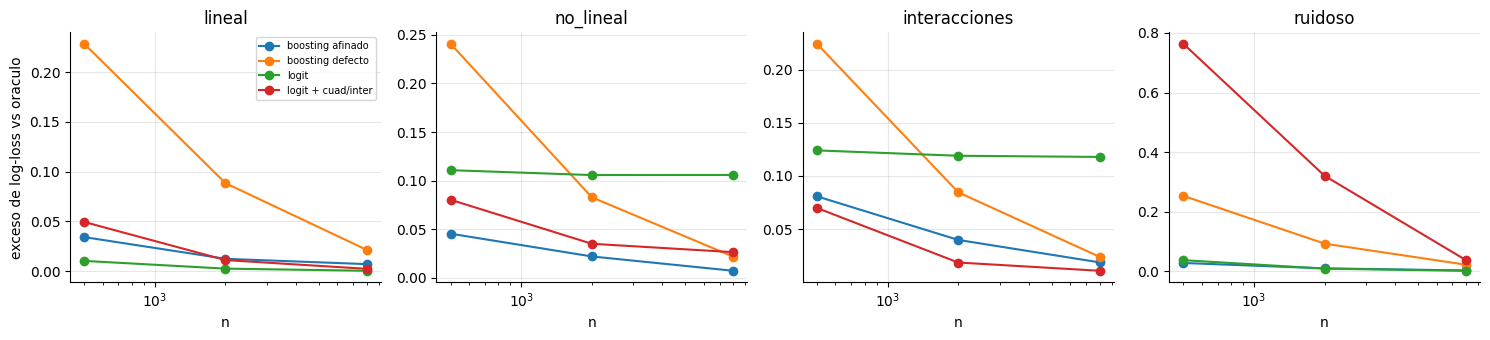

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.5), sharey=False)
for a, mundo in zip(ax, MUNDOS):
    for modelo in t.columns: a.plot(NS, [t.loc[(mundo, n), modelo] for n in NS], "o-", label=modelo)
    a.set_xscale("log"); a.set_title(mundo); a.set_xlabel("n"); a.grid(alpha=0.3)
ax[0].set_ylabel("exceso de log-loss vs oraculo"); ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

**Qué se aprende.** No hay un ganador universal. Con una relación **lineal** la logística es difícil de superar. Con **interacciones y umbrales**, solo el boosting las captura, y su ventaja crece con $n$ porque necesita datos para aprender la estructura. Con **mucho ruido** y pocas señales, la flexibilidad adicional cuesta.

## 5. Probabilidades: ¿están calibradas?

Para decisiones (precios, provisiones) importa que $\hat p$ sea una **probabilidad**, no solo un orden. Se mide la calibración con el **error de calibración esperado** (ECE) y se recalibra con regresión isotónica o con escalamiento de Platt dentro del entrenamiento (validación cruzada).

In [7]:
def ece(y, p, bins=10):
    g = np.minimum((p * bins).astype(int), bins - 1); tot = 0.0
    for b in range(bins):
        m = g == b
        if m.any(): tot += m.mean() * abs(y[m].mean() - p[m].mean())
    return tot

X, y, _ = generar("interacciones", 3000, 7); Xt, yt, pt = generar("interacciones", 20_000, 8)
base = HistGradientBoostingClassifier(random_state=0, max_iter=300, learning_rate=0.1, max_leaf_nodes=15)
variantes = {"boosting crudo": base.fit(X, y),
             "isotonica (CV)": CalibratedClassifierCV(HistGradientBoostingClassifier(random_state=0, max_iter=300, learning_rate=0.1, max_leaf_nodes=15), method="isotonic", cv=5).fit(X, y),
             "Platt (CV)": CalibratedClassifierCV(HistGradientBoostingClassifier(random_state=0, max_iter=300, learning_rate=0.1, max_leaf_nodes=15), method="sigmoid", cv=5).fit(X, y)}
cal = pd.DataFrame({nombre: {"ECE": ece(yt, m.predict_proba(Xt)[:, 1]), "logloss": log_loss(yt, np.clip(m.predict_proba(Xt)[:, 1], 1e-9, 1 - 1e-9)), "AUC": roc_auc_score(yt, m.predict_proba(Xt)[:, 1])} for nombre, m in variantes.items()}).T
cal.loc["oraculo"] = {"ECE": ece(yt, pt), "logloss": log_loss(yt, pt), "AUC": roc_auc_score(yt, pt)}
cal.round(4)

,ECE,logloss,AUC
boosting crudo,0.0715,0.5265,0.7379
isotonica (CV),0.0160,0.4817,0.7439
Platt (CV),0.0141,0.4804,0.7455
oraculo,0.0050,0.4371,0.7951


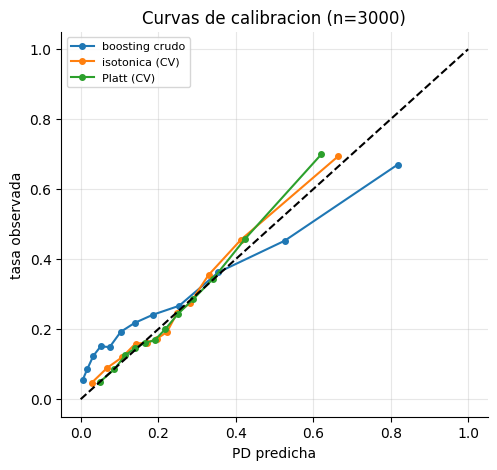

Lectura:
  ECE: crudo 0.0715 | isotonica 0.0160 | Platt 0.0141 | oraculo 0.0050 (ruido de muestreo del propio ECE).
  Log-loss: crudo 0.5265 -> isotonica 0.4817 | Platt 0.4804. El AUC apenas cambia: recalibrar mueve niveles, no ordenamiento.


In [8]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for nombre, m in list(variantes.items()):
    p = m.predict_proba(Xt)[:, 1]; g = pd.qcut(p, 12, duplicates="drop"); d = pd.DataFrame({"p": p, "y": yt, "g": g}).groupby("g", observed=True).mean()
    ax.plot(d["p"], d["y"], "o-", label=nombre, ms=4)
ax.plot([0, 1], [0, 1], "k--"); ax.set_xlabel("PD predicha"); ax.set_ylabel("tasa observada"); ax.legend(fontsize=8); ax.set_title("Curvas de calibracion (n=3000)"); plt.show()
print("Lectura:")
print(f"  ECE: crudo {cal.loc['boosting crudo', 'ECE']:.4f} | isotonica {cal.loc['isotonica (CV)', 'ECE']:.4f} | Platt {cal.loc['Platt (CV)', 'ECE']:.4f} | oraculo {cal.loc['oraculo', 'ECE']:.4f} (ruido de muestreo del propio ECE).")
print(f"  Log-loss: crudo {cal.loc['boosting crudo', 'logloss']:.4f} -> isotonica {cal.loc['isotonica (CV)', 'logloss']:.4f} | Platt {cal.loc['Platt (CV)', 'logloss']:.4f}. El AUC apenas cambia: recalibrar mueve niveles, no ordenamiento.")

## 6. Importancia de variables: una trampa clásica

La **importancia por impureza** de un bosque aleatorio (la que `sklearn` calcula por defecto) tiende a **favorecer variables continuas con muchos valores posibles**, aunque sean ruido, porque ofrecen más puntos de corte. La **importancia por permutación** (medida en datos de prueba) no tiene ese sesgo. Se simula un mundo con 3 variables verdaderas, una variable **continua inútil** y una **binaria inútil**.

In [9]:
def mundo_importancia(n, seed):
    rg = np.random.default_rng(seed); X = rg.standard_normal((n, 5))                # x0,x1,x2 verdaderas; x3 continua inutil; x4 binaria inutil
    X[:, 4] = (rg.random(n) < 0.5).astype(float)
    z = 1.0 * X[:, 0] + 0.7 * X[:, 1] + 0.4 * X[:, 2] - 0.8; y = (rg.random(n) < 1 / (1 + np.exp(-z))).astype(int); return X, y

NOMBRES = ["verd_fuerte", "verd_media", "verd_debil", "ruido_continuo", "ruido_binario"]
imp_gini, imp_perm = [], []
for s in range(20):
    X, y = mundo_importancia(1500, s); Xt, yt = mundo_importancia(5000, 5000 + s)
    rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=1, random_state=0, n_jobs=-1).fit(X, y)
    imp_gini.append(rf.feature_importances_)
    pi = permutation_importance(rf, Xt, yt, n_repeats=5, random_state=0, scoring="roc_auc", n_jobs=-1); imp_perm.append(np.clip(pi.importances_mean, 0, None) / max(pi.importances_mean.sum(), 1e-12))
imp = pd.DataFrame({"impureza": np.mean(imp_gini, axis=0), "permutacion": np.mean(imp_perm, axis=0)}, index=NOMBRES)
imp.round(3)

,impureza,permutacion
verd_fuerte,0.3300,0.6120
verd_media,0.2550,0.2930
verd_debil,0.2080,0.0960
ruido_continuo,0.1830,0.0040
ruido_binario,0.0250,0.0020


In [10]:
print("Lectura:")
print(f"  Por IMPUREZA, la variable continua INUTIL recibe {imp.loc['ruido_continuo', 'impureza']:.0%} de la importancia total (casi como la verdadera debil, {imp.loc['verd_debil', 'impureza']:.0%}) mientras la binaria inutil recibe solo {imp.loc['ruido_binario', 'impureza']:.0%}: el sesgo es hacia la cardinalidad, no hacia la senal.")
print(f"  Por PERMUTACION (datos de prueba), la variable inutil recibe {imp.loc['ruido_continuo', 'permutacion']:.0%} y la binaria {imp.loc['ruido_binario', 'permutacion']:.0%}: ~0, como corresponde.")
print(f"  El orden verdadero (fuerte > media > debil > ruido) {'se respeta' if imp['permutacion'].iloc[0] > imp['permutacion'].iloc[1] > imp['permutacion'].iloc[2] > imp['permutacion'].iloc[3] else 'no se respeta'} con la permutacion.")

Lectura:
  Por IMPUREZA, la variable continua INUTIL recibe 18% de la importancia total (casi como la verdadera debil, 21%) mientras la binaria inutil recibe solo 2%: el sesgo es hacia la cardinalidad, no hacia la senal.
  Por PERMUTACION (datos de prueba), la variable inutil recibe 0% y la binaria 0%: ~0, como corresponde.
  El orden verdadero (fuerte > media > debil > ruido) se respeta con la permutacion.


## 7. ¿Qué tan fiable es la puntuación del CV que elige?

Al **afinar hiperparámetros** con validación cruzada y reportar la **mejor** puntuación del mismo CV, se espera cierto **optimismo de selección**: se eligió la configuración cuyo CV salió mejor, en parte por azar. Se mide la diferencia entre la mejor puntuación del CV y el desempeño en datos frescos (15.000 filas) con una malla de 24 configuraciones y $n=400$, en dos mundos: `ruidoso` (señal débil, AUC del oráculo 0,67) y `nulo` (el resultado es **independiente** de las variables: AUC verdadero 0,5 para cualquier modelo).

*Hipótesis de partida*: el optimismo medio será claramente positivo. La corrida lo desmintió: el sesgo medio es pequeño; lo grande es la **dispersión** de la puntuación (ver abajo).

In [11]:
malla = {"learning_rate": [0.02, 0.05, 0.1, 0.2], "max_leaf_nodes": [3, 6, 12], "l2_regularization": [0.0, 1.0]}

def un_mundo(nombre, s):
    if nombre == "ruidoso":
        X, y, _ = generar("ruidoso", 400, 30_000 + s); Xt, yt, _ = generar("ruidoso", 15_000, 31_000 + s)
    else:                                                               # nulo: y independiente de X
        rg = np.random.default_rng(900 + s); X = rg.standard_normal((400, 30)); y = (rg.random(400) < .25).astype(int)
        Xt = rg.standard_normal((15_000, 30)); yt = (rg.random(15_000) < .25).astype(int)
    gs = GridSearchCV(HistGradientBoostingClassifier(random_state=0, max_iter=100), malla, cv=KFold(5, shuffle=True, random_state=s), scoring="roc_auc").fit(X, y)
    return gs.best_score_, roc_auc_score(yt, gs.predict_proba(Xt)[:, 1])

filas = []
for mundo in ("ruidoso", "nulo"):
    for s in range(20):
        cv, fr = un_mundo(mundo, s); filas.append({"mundo": mundo, "AUC_CV_mejor": cv, "AUC_datos_frescos": fr})
opt = pd.DataFrame(filas); opt["optimismo"] = opt["AUC_CV_mejor"] - opt["AUC_datos_frescos"]
resumen = opt.groupby("mundo").agg(cv_medio=("AUC_CV_mejor", "mean"), cv_sd=("AUC_CV_mejor", "std"), cv_max=("AUC_CV_mejor", "max"), fresco_medio=("AUC_datos_frescos", "mean"),
                                  optimismo_medio=("optimismo", "mean"), optimismo_sd=("optimismo", "std"), pct_optimista=("optimismo", lambda x: (x > 0).mean()), rmse=("optimismo", lambda x: np.sqrt((x ** 2).mean())))
resumen.round(4)

,cv_medio,cv_sd,cv_max,fresco_medio,optimismo_medio,optimismo_sd,pct_optimista,rmse
mundo,,,,,,,,
nulo,0.5084,0.0485,0.6063,0.4971,0.0113,0.0476,0.5000,0.0478
ruidoso,0.5955,0.0428,0.6837,0.5888,0.0067,0.0376,0.5000,0.0373


In [12]:
r, n_ = resumen.loc["ruidoso"], resumen.loc["nulo"]
print("Lectura:")
print(f"  Mundo ruidoso: el CV que elige reporta AUC {r.cv_medio:.3f}; en datos frescos {r.fresco_medio:.3f}. Optimismo medio {r.optimismo_medio:+.3f} (positivo en {r.pct_optimista:.0%} de las repeticiones): casi sin sesgo medio, pero con desvio {r.optimismo_sd:.3f}.")
print(f"  Mundo nulo (AUC verdadero 0.5): el CV reporta en promedio {n_.cv_medio:.3f}, con maximo {n_.cv_max:.3f} y desvio {n_.cv_sd:.3f}. En {(opt[opt.mundo == 'nulo']['AUC_CV_mejor'] > 0.55).mean():.0%} de las repeticiones el CV 'encontro' un AUC superior a 0.55 en datos que no contienen senal.")
print(f"  El error tipico de la puntuacion del CV frente a datos frescos (RMSE) es {r.rmse:.3f} (ruidoso) y {n_.rmse:.3f} (nulo): del orden de las diferencias entre modelos que se suelen comparar.")
print("  Conclusion corregida: con n pequeno el problema principal del CV no es el sesgo medio sino su DISPERSION; reportar solo la mejor puntuacion sin un intervalo (o sin CV anidado) puede confundir ruido con senal.")

Lectura:
  Mundo ruidoso: el CV que elige reporta AUC 0.595; en datos frescos 0.589. Optimismo medio +0.007 (positivo en 50% de las repeticiones): casi sin sesgo medio, pero con desvio 0.038.
  Mundo nulo (AUC verdadero 0.5): el CV reporta en promedio 0.508, con maximo 0.606 y desvio 0.049. En 20% de las repeticiones el CV 'encontro' un AUC superior a 0.55 en datos que no contienen senal.
  El error tipico de la puntuacion del CV frente a datos frescos (RMSE) es 0.037 (ruidoso) y 0.048 (nulo): del orden de las diferencias entre modelos que se suelen comparar.
  Conclusion corregida: con n pequeno el problema principal del CV no es el sesgo medio sino su DISPERSION; reportar solo la mejor puntuacion sin un intervalo (o sin CV anidado) puede confundir ruido con senal.


## 8. Pruebas automáticas

In [13]:
# 8.1 el oraculo es el techo: ningun modelo tiene menor log-loss que la probabilidad verdadera
assert (res["exceso_logloss"] > -1e-3).all(), "un modelo no puede superar al oraculo en log-loss (salvo ruido de muestreo del test)"
# 8.2 mundo lineal: la logistica es competitiva (exceso pequeno) y el boosting no la supera de forma clara con n pequeno
assert t.loc[("lineal", 500), "logit"] < t.loc[("lineal", 500), "boosting defecto"]
assert t.loc[("lineal", 8000), "logit"] < 0.01
# 8.3 interacciones: el boosting afinado supera a la logistica simple, y su ventaja crece con n
assert t.loc[("interacciones", 8000), "boosting afinado"] < t.loc[("interacciones", 8000), "logit"]
adv = lambda n: t.loc[("interacciones", n), "logit"] - t.loc[("interacciones", n), "boosting afinado"]
assert adv(8000) > adv(500)
# 8.4 no lineal aditivo: los terminos cuadraticos ayudan frente a la logistica simple, pero no capturan el seno por completo
assert t.loc[("no_lineal", 8000), "logit + cuad/inter"] < t.loc[("no_lineal", 8000), "logit"]
assert t.loc[("no_lineal", 8000), "boosting afinado"] < t.loc[("no_lineal", 8000), "logit"]
# 8.5 el exceso de la logistica en un mundo no lineal/interactivo no baja con n (error de modelo, no de muestra)
assert t.loc[("interacciones", 8000), "logit"] > 0.5 * t.loc[("interacciones", 500), "logit"]
# 8.6 ruidoso: el modelo simple no pierde frente al boosting con n pequeno
assert t.loc[("ruidoso", 500), "logit"] <= t.loc[("ruidoso", 500), "boosting defecto"] + 0.01
# 8.7 recalibrar mejora el ECE y el log-loss sin cambiar apreciablemente el AUC
assert min(cal.loc["isotonica (CV)", "logloss"], cal.loc["Platt (CV)", "logloss"]) <= cal.loc["boosting crudo", "logloss"] + 1e-3
assert abs(cal.loc["isotonica (CV)", "AUC"] - cal.loc["boosting crudo", "AUC"]) < 0.03
# 8.8 importancia: la impureza infla la variable continua inutil (corregido: no supera a la debil, pero recibe >10% y >3x la binaria inutil); la permutacion no
assert imp.loc["ruido_continuo", "impureza"] > 0.10 and imp.loc["ruido_continuo", "impureza"] > 3 * imp.loc["ruido_binario", "impureza"]
assert imp.loc["ruido_continuo", "permutacion"] < 0.05 and imp.loc["ruido_binario", "permutacion"] < 0.05
assert imp["permutacion"].iloc[0] > imp["permutacion"].iloc[1] > imp["permutacion"].iloc[2]
# 8.9 puntuacion del CV con n pequeno: sin sesgo medio grande pero muy dispersa (hipotesis inicial de optimismo >0.02 REFUTADA)
assert abs(r.optimismo_medio) < 0.03 and r.optimismo_sd > 0.025 and r.rmse > 0.025
assert abs(n_.fresco_medio - 0.5) < 0.01 and n_.cv_max > 0.58 and n_.cv_sd > 0.03
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Mundo lineal | La logística es muy difícil de superar y el boosting solo añade varianza | Empezar por el modelo simple y comparar |
| Interacciones y umbrales | El boosting afinado gana y su ventaja crece con n; la logística simple no las ve aunque haya muchos datos | Usar boosting cuando se sospechen interacciones; confirmar con una comparación justa |
| No lineal aditivo | Los términos cuadráticos ayudan, pero el seno solo lo recoge del todo un modelo flexible | Un modelo parametrizado con formas adecuadas puede ser casi tan bueno y más interpretable |
| Mucho ruido | Con pocos datos y muchas variables inútiles, flexibilidad extra cuesta | Regularizar y reducir variables antes de usar un modelo muy flexible |
| Probabilidades | Las probabilidades crudas del boosting pueden estar mal calibradas; recalibrar mejora log-loss sin tocar el orden | Calibrar si las probabilidades se usan para decidir |
| Importancia de variables | La importancia por impureza infla una variable continua inútil; la de permutación no | Usar permutación en datos de prueba |
| Selección de hiperparámetros | Con n pequeño el sesgo medio del CV que elige es pequeño, pero su dispersión es grande y puede 'encontrar' señal en datos sin señal | Reportar intervalos; usar CV anidado o un conjunto de prueba separado |

**Límites que no deben ocultarse**

- Los mundos son estilizados y con pocas variables; en datos reales la estructura es una mezcla de todos ellos.
- Se usan pocas repeticiones (5 por celda) para acotar el tiempo; las diferencias pequeñas entre modelos están dentro del ruido.
- La malla de afinación es pequeña; una búsqueda más amplia mejoraría el boosting a costa de más optimismo de selección.
- El oráculo supone conocer la probabilidad verdadera, algo imposible en la práctica.
- Datos sintéticos: ningún valor numérico es extrapolable a un problema real.